In [1]:
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

In [2]:
target = "ClosePrice"

def n_months(path):
    return int(re.search(r"(\d+)mo_test", str(path)).group(1))

def metrics(y_true, y_pred):
    ape = np.abs(y_pred - y_true) / y_true

    return {
        "R2": r2_score(y_true, y_pred),
        "MAPE_%": ape.mean() * 100,
        "MdAPE_%": np.median(ape) * 100,
        "MAE_$": mean_absolute_error(y_true, y_pred)
    }

split_dirs = sorted(
    glob.glob("data/sold/split/*mo_test_2026-08"),
    key=n_months
)

In [3]:
rows = []

for folder in split_dirs:

    months = n_months(folder)

    train = pd.read_csv(f"{folder}/train.csv")
    test = pd.read_csv(f"{folder}/test.csv")

    X_tr = train.drop(columns=target)
    y_tr = train[target]

    X_te = test.drop(columns=target)
    y_te = test[target]

    models = {
        "DecisionTree": DecisionTreeRegressor(
            max_depth=5,
            random_state=42
        ),

        "RandomForest": RandomForestRegressor(
            n_estimators=50,
            max_features=0.5,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        )
    }

    for name, model in models.items():

        model.fit(X_tr, y_tr)
        pred = model.predict(X_te)

        rows.append({
            "model": name,
            "n_train_months": months,
            "n_train_rows": len(X_tr),
            **{
                f"test_{k}": v
                for k, v in metrics(y_te, pred).items()
            },
            "neg_preds": int((pred <= 0).sum()),
        })

        pd.DataFrame(rows).to_csv(
            "tree_forest_results.csv",
            index=False
        )

results = pd.DataFrame(rows)

display(results)


,model,n_train_months,n_train_rows,test_R2,test_MAPE_%,test_MdAPE_%,test_MAE_$,neg_preds
0,DecisionTree,6,70134,0.682994,25.746123,17.094509,320449.271197,0
1,RandomForest,6,70134,0.797694,13.636647,8.362879,196750.692935,0
2,DecisionTree,9,97808,0.685024,24.485096,16.779988,313961.282836,0
3,RandomForest,9,97808,0.809663,13.196029,8.206882,191707.239696,0
4,DecisionTree,12,132729,0.682806,24.040799,16.468452,308285.802788,0
5,RandomForest,12,132729,0.816209,12.723993,7.957447,185086.959033,0
6,DecisionTree,15,168303,0.703086,23.781141,16.299382,304797.811885,0
7,RandomForest,15,168303,0.820912,12.625036,7.839100,183834.462393,0
8,DecisionTree,18,199629,0.681468,24.180973,16.460713,310084.240181,0
9,RandomForest,18,199629,0.822870,12.519220,7.767029,181458.176554,0


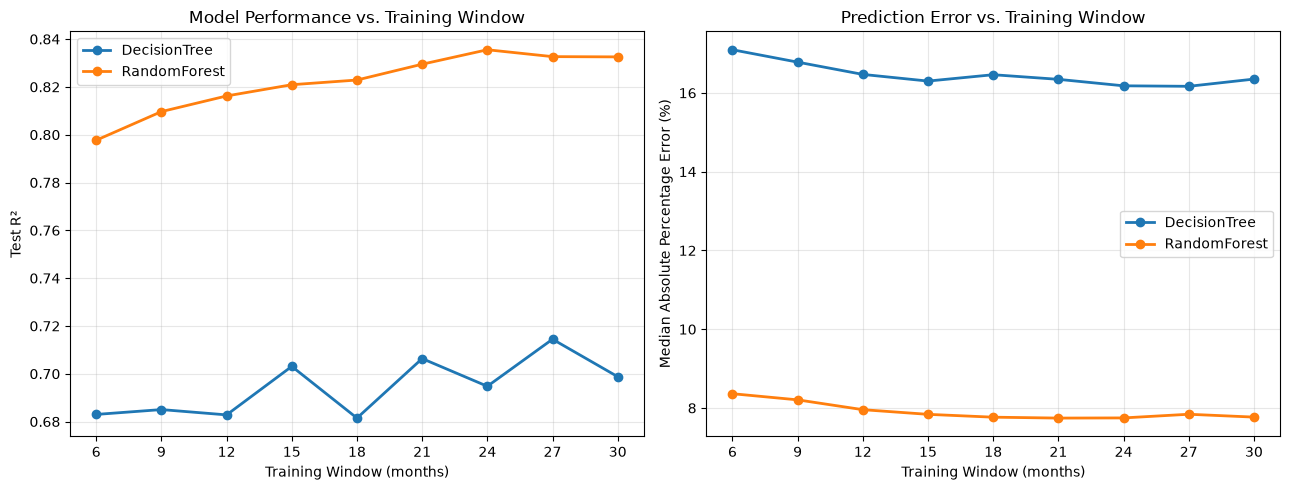

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, group in results.groupby("model"):

    group = group.sort_values("n_train_months")

    axes[0].plot(
        group["n_train_months"],
        group["test_R2"],
        marker="o",
        linewidth=2,
        label=name
    )

    axes[1].plot(
        group["n_train_months"],
        group["test_MdAPE_%"],
        marker="o",
        linewidth=2,
        label=name
    )

axes[0].set(
    xlabel="Training Window (months)",
    ylabel="Test R²",
    title="Model Performance vs. Training Window"
)

axes[1].set(
    xlabel="Training Window (months)",
    ylabel="Median Absolute Percentage Error (%)",
    title="Prediction Error vs. Training Window"
)

for ax in axes:
    ax.set_xticks(sorted(results["n_train_months"].unique()))
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

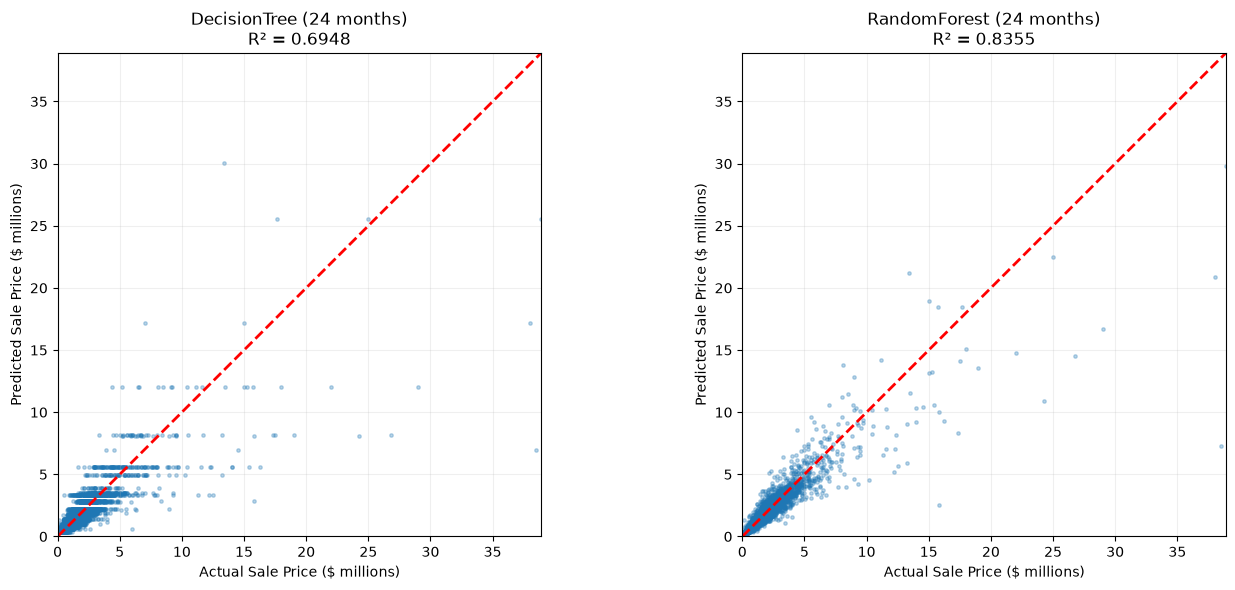

In [12]:
MONTHS = 24

folder = f"data/sold/split/{MONTHS}mo_test_2026-08"

train = pd.read_csv(f"{folder}/train.csv")
test = pd.read_csv(f"{folder}/test.csv")

X_tr = train.drop(columns=target)
y_tr = train[target]

X_te = test.drop(columns=target)
y_te = test[target]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (name, model) in zip(axes, models.items()):

    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)

    actual_millions = y_te / 1_000_000
    predicted_millions = pred / 1_000_000

    ax.scatter(
        actual_millions,
        predicted_millions,
        s=6,
        alpha=0.3
    )

    limit = max(
        actual_millions.max(),
        predicted_millions.max()
    )

    ax.plot(
        [0, limit],
        [0, limit],
        "r--",
        linewidth=2,
    )

    ax.set_xlabel("Actual Sale Price ($ millions)")
    ax.set_ylabel("Predicted Sale Price ($ millions)")

    ax.set_title(
        f"{name} ({MONTHS} months)\n"
        f"R² = {r2_score(y_te, pred):.4f}"
    )

    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)
    ax.set_aspect("equal", adjustable="box")

    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()